# 3.2 Linear Regression on Lagged PM2.5 (Nairobi)

**Purpose.** Build a first forecasting model for Nairobi PM2.5: predict the next hourly reading from the previous hour, and test whether it beats the naive "next hour = this hour" baseline.

**Method.**
1. Load the cleaned hourly series with `wrangle_data()` from lesson 3.1.
2. Plot the series and create a one-hour lag feature (`lag_1`).
3. Split chronologically (first 80% train, last 20% test), with no shuffling.
4. Compare a persistence baseline with a linear regression on `lag_1`, using MAE, RMSE and R².

**Data note.** The hourly series combines readings from 10 sensors, one sensor per hour, so it is not a single instrument's record. This is revisited under limitations.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt

from mongo_wrangle import wrangle_data

DB = "air-quality"
COLLECTION = "nairobi"

df = wrangle_data(DB, COLLECTION)

print(f"Loaded {len(df):,} records")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"Index timezone: {df.index.tz}")
print(f"Index sorted: {df.index.is_monotonic_increasing}")

df_2024 = df.loc["2024"]
print(f"\n2024 rows: {len(df_2024):,}")
print(f"2024 range: {df_2024.index.min()} to {df_2024.index.max()}")
print("\nGaps between consecutive 2024 timestamps:")
print(df_2024.index.to_series().diff().value_counts())

df.head()

Loaded 10,000 records
Date range: 2024-01-01 03:00:00+03:00 to 2025-02-20 18:00:00+03:00
Index timezone: Africa/Nairobi
Index sorted: True

2024 rows: 8,781
2024 range: 2024-01-01 03:00:00+03:00 to 2024-12-31 23:00:00+03:00

Gaps between consecutive 2024 timestamps:
timestamp
0 days 01:00:00    8780
Name: count, dtype: int64


,pm25
timestamp,
2024-01-01 03:00:00+03:00,45.42
2024-01-01 04:00:00+03:00,28.71
2024-01-01 05:00:00+03:00,30.34
2024-01-01 06:00:00+03:00,28.35
2024-01-01 07:00:00+03:00,52.78


# 3.2 Linear Regression in Time Series Data

## Objective

Explore whether previous hourly PM2.5 readings can help predict future readings using linear regression.

We will:
- Retrieve the hourly PM2.5 time series from MongoDB.
- Visualise the data.
- Create lag features.
- Split the data chronologically into training and test sets.
- Compare a persistence baseline against a linear regression model.
- Evaluate model performance using MAE, RMSE and R².

**Important limitation:** The combined hourly series contains readings from multiple sensors. Consecutive observations may therefore come from different sensors.

In [3]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src.mongo_wrangle import wrangle_data

In [4]:
DB = "air-quality"
COLLECTION = "nairobi"

df = wrangle_data(DB, COLLECTION)

print("Dataset shape:", df.shape)
print("\nDate range:")
print(df.index.min(), "to", df.index.max())

df.head()

Dataset shape: (10000, 1)

Date range:
2024-01-01 03:00:00+03:00 to 2025-02-20 18:00:00+03:00


,pm25
timestamp,
2024-01-01 03:00:00+03:00,45.42
2024-01-01 04:00:00+03:00,28.71
2024-01-01 05:00:00+03:00,30.34
2024-01-01 06:00:00+03:00,28.35
2024-01-01 07:00:00+03:00,52.78


## 1. Visualising the time series

Before modelling, we examine how PM2.5 concentrations change over time.

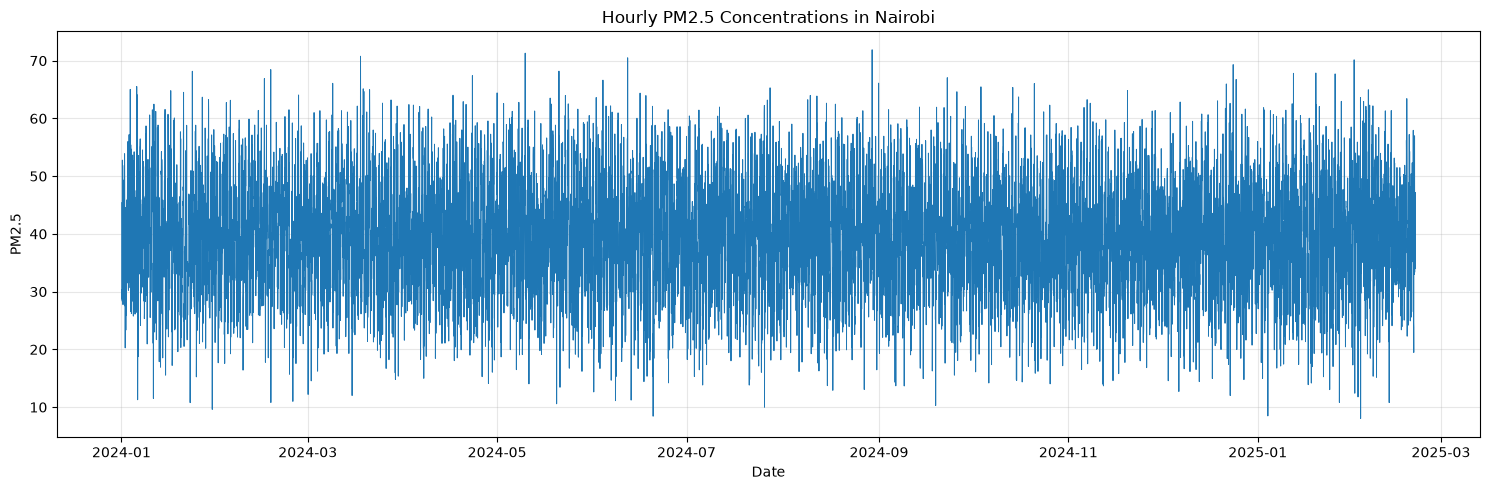

In [5]:
# Plot the PM2.5 time series
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["pm25"], linewidth=0.7)

plt.title("Hourly PM2.5 Concentrations in Nairobi")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Creating lag features

A lag feature uses an earlier observation to help predict a later one.

Because our dataset is hourly:
- lag_1 represents the previous hour.
- lag_2 represents two hours earlier.
- lag_3 represents three hours earlier.
- lag_7 represents seven hours earlier.

These are not daily or weekly lags.

In [6]:
# Create lag features
df["lag_1"] = df["pm25"].shift(1)

df["lag_2"] = df["pm25"].shift(2)

df["lag_3"] = df["pm25"].shift(3)

df["lag_7"] = df["pm25"].shift(7)

# Remove rows with missing lag values
df_lags = df.dropna().copy()

print("Original dataset:", df.shape)
print("Dataset after creating lags:", df_lags.shape)

df_lags.head(10)

Original dataset: (10000, 5)
Dataset after creating lags: (9993, 5)


,pm25,lag_1,lag_2,lag_3,lag_7
timestamp,,,,,
2024-01-01 10:00:00+03:00,43.24,28.61,43.49,52.78,45.42
2024-01-01 11:00:00+03:00,43.45,43.24,28.61,43.49,28.71
2024-01-01 12:00:00+03:00,27.75,43.45,43.24,28.61,30.34
2024-01-01 13:00:00+03:00,37.90,27.75,43.45,43.24,28.35
2024-01-01 14:00:00+03:00,30.66,37.90,27.75,43.45,52.78
2024-01-01 15:00:00+03:00,34.50,30.66,37.90,27.75,43.49
2024-01-01 16:00:00+03:00,44.79,34.50,30.66,37.90,28.61
2024-01-01 17:00:00+03:00,49.31,44.79,34.50,30.66,43.24
2024-01-01 18:00:00+03:00,36.90,49.31,44.79,34.50,43.45


## 3. Preparing training and test data

We use a chronological 80/20 split. Earlier observations are used for training, while later observations are reserved for testing.

We begin with a single predictor: `lag_1`, the previous hourly PM2.5 reading.

In [7]:
# Select 2024 observations
df_2024 = df_lags.loc["2024"].copy()

# Define predictor and target
X = df_2024[["lag_1"]]
y = df_2024["pm25"]

# Chronological 80/20 split
split_index = int(len(df_2024) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Inspect the split
print("Total observations:", len(df_2024))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Total observations: 8774
Training observations: 7019
Testing observations: 1755

Training period:
2024-01-01 10:00:00+03:00 to 2024-10-19 20:00:00+03:00

Testing period:
2024-10-19 21:00:00+03:00 to 2024-12-31 23:00:00+03:00


## 4. Baseline and linear regression model

We first establish a persistence baseline, using the previous hourly reading as the prediction.

We then train a linear regression model using `lag_1` as the predictor.

Both approaches are evaluated on the same chronological test set.

In [9]:
# 1. Persistence baseline
y_pred_baseline = X_test["lag_1"]

# 2. Train linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Generate predictions
y_pred = model.predict(X_test)

# 4. Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Persistence baseline", "Linear regression"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_baseline),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_baseline)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2": [
        r2_score(y_test, y_pred_baseline),
        r2_score(y_test, y_pred)
    ]
})

print("Regression intercept:", model.intercept_)
print("Regression coefficient:", model.coef_[0])

results

Regression intercept: 28.75851042412759
Regression coefficient: 0.27314972547713295


,Model,MAE,RMSE,R2
0,Persistence baseline,9.263578,11.641763,-0.456712
1,Linear regression,7.459089,9.287555,0.072874


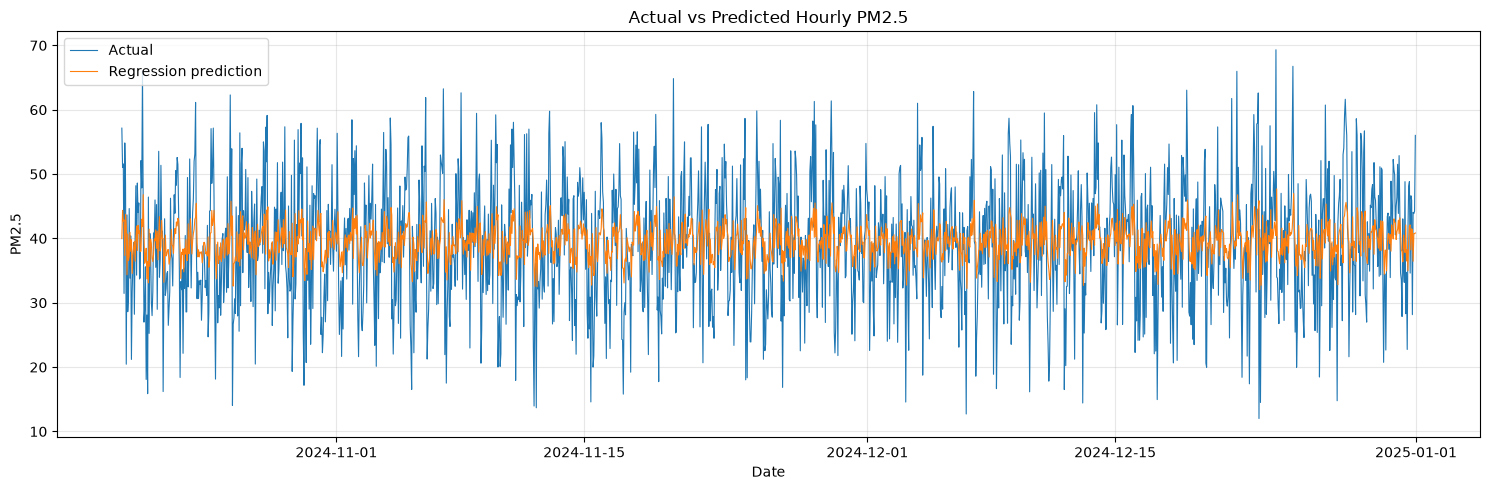

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(y_test.index, y_test, label="Actual", linewidth=0.8)
plt.plot(y_test.index, y_pred, label="Regression prediction", linewidth=0.8)

plt.title("Actual vs Predicted Hourly PM2.5")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

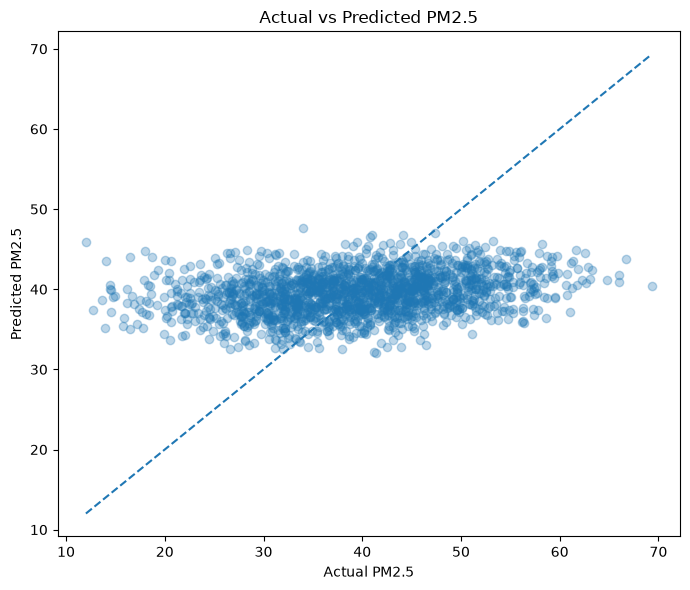

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, linestyle="--")

plt.title("Actual vs Predicted PM2.5")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")

plt.tight_layout()
plt.show()

## 5. Multiple-lag linear regression

We extend the model by including four lag features.

This allows the model to consider several previous hourly readings rather than relying only on the immediately preceding observation.

In [12]:
# Define multiple predictors
features = ["lag_1", "lag_2", "lag_3", "lag_7"]

X_multi = df_2024[features]
y_multi = df_2024["pm25"]

# Chronological split using the same 80/20 boundary
X_train_multi = X_multi.iloc[:split_index]
X_test_multi = X_multi.iloc[split_index:]

y_train_multi = y_multi.iloc[:split_index]
y_test_multi = y_multi.iloc[split_index:]

# Train multiple-lag regression
multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

# Generate predictions
y_pred_multi = multi_model.predict(X_test_multi)

# Evaluate
multi_results = pd.DataFrame({
    "Model": ["Multiple-lag regression"],
    "MAE": [mean_absolute_error(y_test_multi, y_pred_multi)],
    "RMSE": [np.sqrt(mean_squared_error(y_test_multi, y_pred_multi))],
    "R2": [r2_score(y_test_multi, y_pred_multi)]
})

multi_results

,Model,MAE,RMSE,R2
0,Multiple-lag regression,7.377096,9.199297,0.09041


In [13]:
all_results = pd.concat(
    [results, multi_results],
    ignore_index=True
)

all_results.round(4)

,Model,MAE,RMSE,R2
0,Persistence baseline,9.2636,11.6418,-0.4567
1,Linear regression,7.4591,9.2876,0.0729
2,Multiple-lag regression,7.3771,9.1993,0.0904


In [14]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": multi_model.coef_
})

print("Intercept:", multi_model.intercept_)
coefficients

Intercept: 27.035144419192264


,Feature,Coefficient
0,lag_1,0.228679
1,lag_2,0.115486
2,lag_3,0.054011
3,lag_7,-0.081469


## 6. Model comparison and findings

Three approaches were evaluated using a chronological 80/20 train/test split:

1. Persistence baseline.
2. Single-lag linear regression.
3. Multiple-lag linear regression using four hourly lag features.

### Results

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Persistence baseline | 9.2636 | 11.6418 | -0.4567 |
| Single-lag regression | 7.4591 | 9.2876 | 0.0729 |
| Multiple-lag regression | 7.3771 | 9.1993 | 0.0904 |

### Initial interpretation

Multiple-lag regression achieved the best performance, although its improvement over single-lag regression was modest.

Both regression models outperformed the persistence baseline.

The relatively low R² values indicate that lagged PM2.5 readings alone explain only a small proportion of the variation in the test observations.

### Limitations

- The combined hourly dataset contains readings from multiple sensors.
- Consecutive readings may therefore originate from different sensors.
- Only historical PM2.5 readings were used as predictors.
- The evaluation represents rolling one-hour-ahead predictions, not long-term forecasting.
- Model performance may be affected by sensor differences and other environmental factors not included in the model.

### Multiple-lag coefficient interpretation

The multiple-lag regression model produced an intercept of 27.0351.

The coefficients were:

- lag_1: 0.2287
- lag_2: 0.1155
- lag_3: 0.0540
- lag_7: -0.0815

The first three lag features have positive coefficients, while lag_7 has a negative coefficient.

These coefficients represent conditional relationships and should not be interpreted as causal effects.

The model's modest R² of 0.0904 indicates that these four lag features provide limited explanatory power.

In [15]:
print("Single-lag model")
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("\nMultiple-lag model")
print("Intercept:", multi_model.intercept_)
print(pd.Series(multi_model.coef_, index=features))

print("\nFinal model comparison")
display(all_results.round(4))

print("\nNotebook data checks")
print("Original observations:", len(df))
print("2024 observations:", len(df_2024))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Missing values in modelling data:", df_2024.isna().sum().sum())

Single-lag model
Intercept: 28.75851042412759
Coefficient: 0.27314972547713295

Multiple-lag model
Intercept: 27.035144419192264
lag_1    0.228679
lag_2    0.115486
lag_3    0.054011
lag_7   -0.081469
dtype: float64

Final model comparison


,Model,MAE,RMSE,R2
0,Persistence baseline,9.2636,11.6418,-0.4567
1,Linear regression,7.4591,9.2876,0.0729
2,Multiple-lag regression,7.3771,9.1993,0.0904



Notebook data checks
Original observations: 10000
2024 observations: 8774
Training observations: 7019
Testing observations: 1755
Missing values in modelling data: 0
